In [112]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [115]:
discharge = pd.read_csv('./ZI_discharge1985-2025.csv').reset_index()
melange = pd.read_csv('./melange_areas.csv')
terminusarea = pd.read_csv('./terminus_area_change.csv')

### Glacier discharge
Discharge in Gigatons per year (Gt/yr) through a flux gate at Zachariæ Isstrøm.

/var/folders/z2/t78xbk451n74r4q5p4w1zt640000gn/T/ipykernel_92315/1627210811.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  discharge['time'] = pd.to_datetime(discharge['time'])


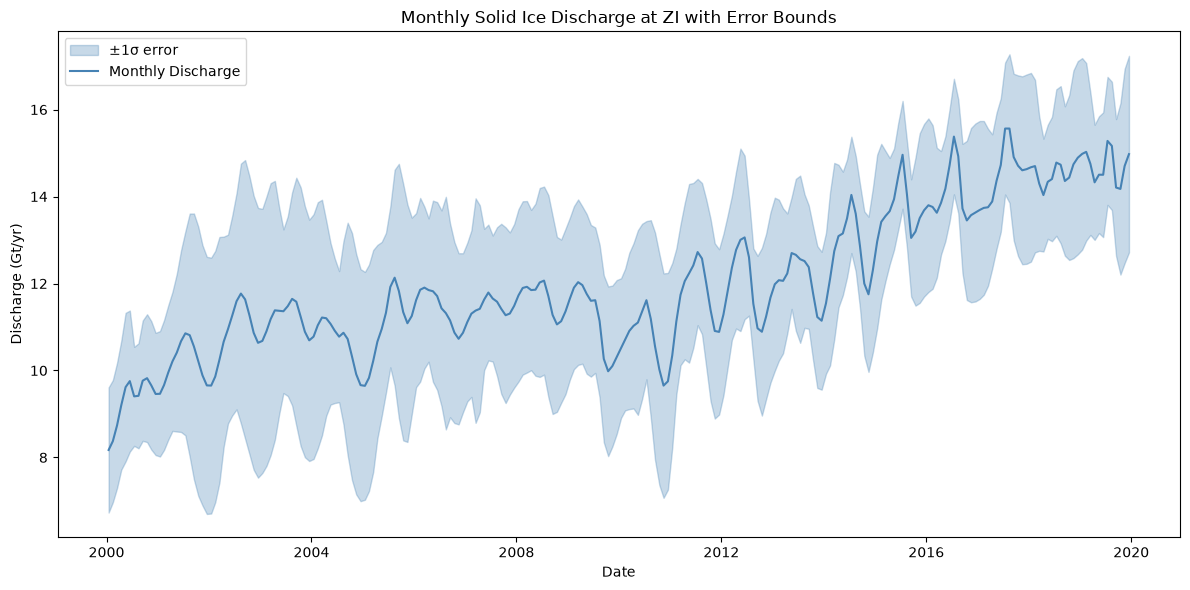

In [121]:
discharge['time'] = pd.to_datetime(discharge['time'])
discharge = discharge[
    (discharge['time'] >= pd.Timestamp('2000-01-01')) &
    (discharge['time'] <= pd.Timestamp('2020-01-01'))
]

plt.figure(figsize=(12, 6))

# Remove NaN values
discharge_clean = discharge.dropna(subset=['Discharge (Gt/yr)', 'Discharge error (1 sigma)'])

# Plot with shaded error bars
plt.fill_between(
    discharge_clean['time'],
    discharge_clean['Discharge (Gt/yr)'] - discharge_clean['Discharge error (1 sigma)'],
    discharge_clean['Discharge (Gt/yr)'] + discharge_clean['Discharge error (1 sigma)'],
    alpha=0.3,
    label='±1σ error',
    color='steelblue'
)
plt.plot(discharge_clean['time'], discharge_clean['Discharge (Gt/yr)'], linewidth=1.5, label='Monthly Discharge', color='steelblue')

plt.ylabel('Discharge (Gt/yr)')
plt.xlabel('Date')
plt.title('Monthly Solid Ice Discharge at ZI with Error Bounds')
plt.legend()
plt.tight_layout()
plt.show()

### Terminus area

The terminus area (km^2) in based on manually digitized terminus positions, relative to an arbitrary upstream line.

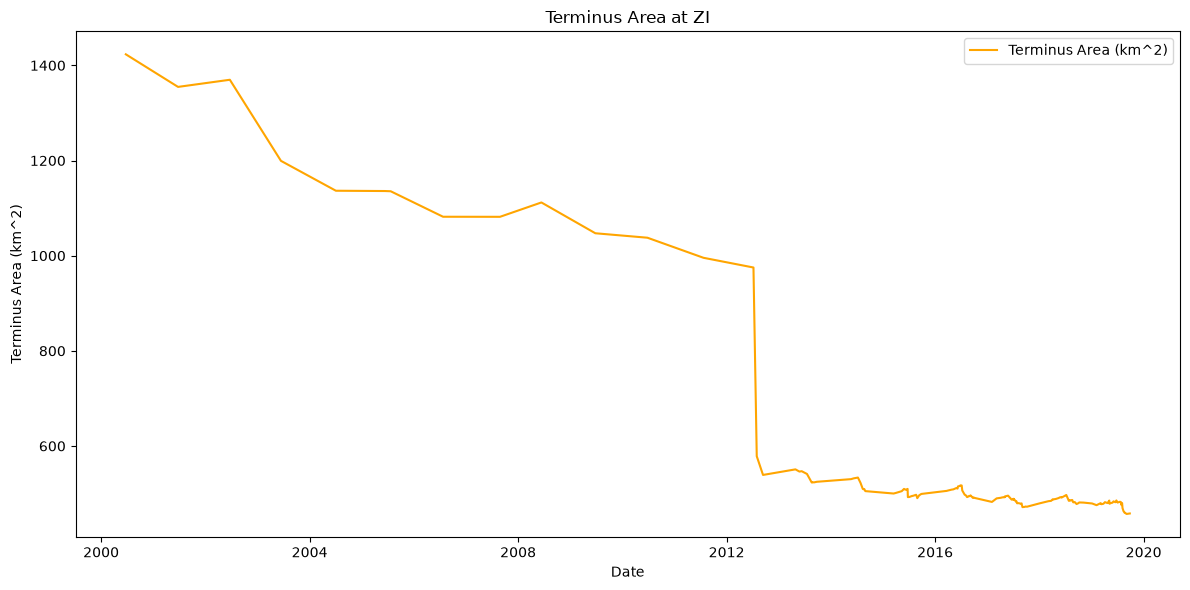

In [116]:
terminusarea['date'] = pd.to_datetime(terminusarea['date'])
terminusarea = terminusarea[
    (terminusarea['date'] >= pd.Timestamp('2000-01-01')) &
    (terminusarea['date'] <= pd.Timestamp('2020-01-01'))
]

plt.figure(figsize=(12, 6))

plt.plot(terminusarea['date'], terminusarea['area_km2'], linewidth=1.5, label='Terminus Area (km^2)', color='orange')

plt.ylabel('Terminus Area (km^2)')
plt.xlabel('Date')
plt.title('Terminus Area at ZI')
plt.legend()
plt.tight_layout()
plt.show()

### Mélange Area

The velocity of rigid glacier mélange (icebergs and sea ice that form in glacier-fed fjords) in ZI's fjord, measured to be moving as a unit via satellite feature tracking.


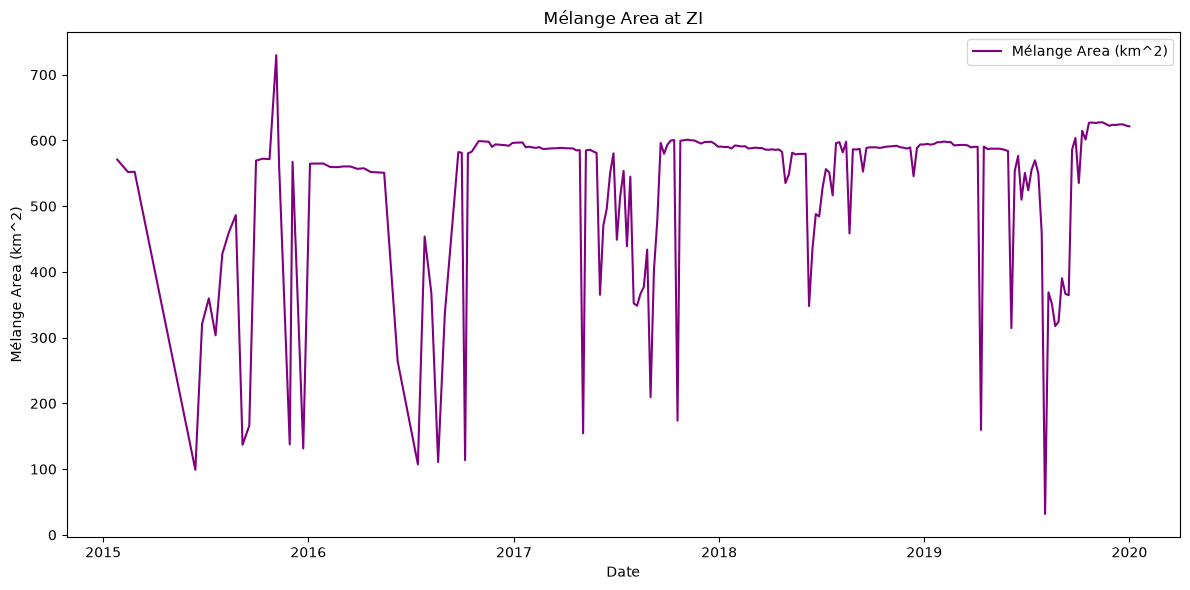

In [108]:
melange['time'] = pd.to_datetime(melange['time'])
melange = melange[
    (melange['time'] >= pd.Timestamp('2000-01-01')) &
    (melange['time'] <= pd.Timestamp('2020-01-01'))
]

plt.figure(figsize=(12, 6))

plt.plot(melange['time'], melange['area_km2'], linewidth=1.5, label='Mélange Area (km^2)', color='purple')

plt.ylabel('Mélange Area (km^2)')
plt.xlabel('Date')
plt.title('Mélange Area at ZI')
plt.legend()
plt.tight_layout()
plt.show()